# Los modelos supervisores de pruebas de estrés, cópulas vine, crecimiento en riesgo y VAR bayesianos

**Pregunta:** Frente a la práctica publicada para agregar riesgos y medir el riesgo de modelo, ¿cuánto esconde una sola cifra de
capital de Banco Andino, y cuánto podría equivocarse el modelo de referencia antes de que su capital cambie?

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 01 a 03 de este tema (la agregación, la banda y sus cotas)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- simular el agregado gaussiano de los cuatro riesgos de Banco Andino y leer su capital, la cifra única que las medidas
  publicadas de riesgo de modelo van a cuestionar;
- leer la práctica publicada sobre modelos supervisores de pruebas de estrés, generadores de escenarios, agregación de riesgos y
  riesgo de modelo, y decir qué implementa el caso y qué deja fuera;
- ejecutar el multiplicador de recargo y la medida relativa de Barrieu y Scandolo sobre los ocho modelos de la banda, y leer lo
  que dicen sobre la dispersión entre los modelos;
- ejecutar el peor caso de Glasserman y Xu dentro de un presupuesto de entropía sobre el agregado simulado, y decir qué tan
  rápido crece;
- comparar el caso con la práctica publicada en los números que se pueden medir en los documentos versionados.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 statsmodels==0.15.0
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee el bloque de agregación de **C18** (Banco Andino), como los notebooks 01 a 03.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 1.1.0 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginales, banda, matriz de correlación y el bloque `model_risk` versionado con los resultados de Barrieu-Scandolo y Glasserman-Xu; y `outputs.backcast` para el ajuste fuera de tiempo de los satélites), `data/derived/C18/t-copula-baseline.json` (la referencia de Rosenberg y Schuermann) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **Las marginales se reconstruyen desde las grillas de cuantiles versionadas, para un paso.** La medida de Glasserman-Xu necesita las pérdidas simuladas del agregado, que el documento no tiene, así que el paso 2 reconstruye las marginales del notebook 02 desde las grillas y simula el agregado gaussiano con la semilla del caso; los números versionados se imprimen al lado.

In [2]:
# El bloque de agregación base, la matriz de correlación, la banda y las grillas de cuantiles versionadas
baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
marginals = agg["marginals"]
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple",
         "variance-covariance": "varianza-covarianza", "gaussian-copula": "cópula gaussiana (referencia)",
         "t-copula": "cópula t", "worst-case": "peor caso"}

## Método

### Paso 1: el capital que se cuestiona

El método propio del caso es la agregación de los notebooks 01 a 03: cuatro marginales, una matriz de correlación, una cópula y
una cifra de capital con una banda alrededor. Este paso lo ejecuta una vez más, como hizo el notebook 02: las cuatro funciones
de cuantiles se reconstruyen desde las grillas versionadas y `simulate_component_losses` genera un millón de pérdidas conjuntas
con la cópula gaussiana y la semilla del caso. Las dos celdas siguientes simulan, y luego leen el VaR, la pérdida esperada en
la cola y el capital económico del total con los estimadores del motor.

In [3]:
# Reconstruir las marginales desde las grillas versionadas y simular el agregado gaussiano de los cuatro riesgos
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
print("escenarios simulados y riesgos", joint.shape)

escenarios simulados y riesgos (1000000, 4)


La celda siguiente lee el VaR y la pérdida esperada en la cola del total con los estimadores del motor y dibuja el histograma
del total en escala logarítmica con ambos marcados.

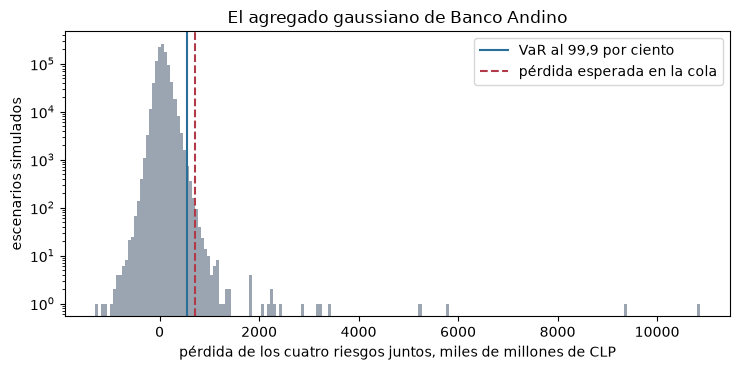

media, VaR y ES del total, millones de CLP
66898.7 558727.5 709402.5
capital económico, VaR menos pérdida esperada 491998.8


In [4]:
# El VaR y la pérdida esperada en la cola del total con los estimadores del motor, y el histograma del total
var_total = rv_port.var_from_sample(total, LEVEL)
es_total = rv_port.es_from_sample(total, LEVEL)
el_total = sum(m["el_clp_m"] for m in marginals)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(total / 1e3, bins=200, color="#9aa5b1", log=True)
ax.axvline(var_total / 1e3, color="#2a6f97", label="VaR al 99,9 por ciento")
ax.axvline(es_total / 1e3, color="#b23a48", linestyle="--", label="pérdida esperada en la cola")
ax.set_xlabel("pérdida de los cuatro riesgos juntos, miles de millones de CLP")
ax.set_ylabel("escenarios simulados")
ax.set_title("El agregado gaussiano de Banco Andino")
ax.legend()
fig.tight_layout()
plt.show()
print("media, VaR y ES del total, millones de CLP")
print(round(total.mean(), 1), round(var_total, 1), round(es_total, 1))
print("capital económico, VaR menos pérdida esperada", round(var_total - el_total, 1))

La media del total es 66.899 millones de pesos, que es su pérdida esperada, y el VaR de 99,9 por ciento queda muy a la derecha,
en 558.727 millones, con la pérdida esperada en la cola todavía más lejos: la cola es pesada, porque el riesgo operacional y el
de crédito tienen colas derechas largas. Restar la pérdida esperada da el capital económico de la cópula gaussiana, el modelo de
referencia de este notebook. Todo lo que sigue le hace la misma pregunta a este único número, cuánto de él es el modelo.

## Comparación

La investigación persistida (dossiers 05 y 06) declara la práctica en torno a cada parte del caso. La tabla la pone junto a lo que hace el caso, con la fuente y el estado de cada afirmación.

| Parte | La práctica publicada | En el caso y en el motor |
|---|---|---|
| **Modelos supervisores de pruebas de estrés** | La Reserva Federal publica ahora la documentación completa de sus modelos (otoño 2026, modelos de riesgo de crédito). La pérdida esperada corporativa es $PD \times LGD \times EAD$ por facilidad; el modelo de PD es un conjunto de 16 regresiones MCO de la PD de un proveedor sobre el diferencial BBB y su rezago de cuatro trimestres, estimadas 2006 a 2023; la LGD se estresa por el diferencial BBB, la EAD por un factor de equivalente de préstamo sobre datos del Shared National Credit; el PPNR tiene su propio conjunto de modelos 2026. | Cinco satélites MCO de tasas de castigo por tipo de préstamo sobre crecimiento del PIB y desempleo, ajustados 1985 a 2019 (notebook 04): una familia más simple y distinta. Los modelos de la Reserva Federal **no pueden replicarse a una tasa de pérdida publicada** desde el registro público, por lo cual el caso C19 sigue planificado (notebook 09). |
| **Abajo-arriba con restricciones** | El ejercicio de la EBA 2025 es una prueba de estrés abajo-arriba restringida: los bancos usan sus propios modelos con parámetros prescritos, con un balance estático y parámetros de referencia donde no existe un satélite adecuado (Nota Metodológica, párrafos 33 a 38 y 122 a 124). | Las reglas estáticas por párrafo se aplican y se prueban (notebook 05); el caso tiene un banco y ningún retador, así que abajo-arriba frente a arriba-abajo es una regla mostrada, no una comparación hecha (notebook 07). |
| **Generadores de escenarios** | VAR bayesianos con a priori de Minnesota (Litterman 1986; Banbura, Giannone y Reichlin 2010), VAR globales, crecimiento en riesgo con una densidad t asimétrica (Adrian, Boyarchenko y Giannone 2019) y un satélite de cuantiles en panel (Covas, Rump y Zakrajsek 2014). | El motor tiene el pronóstico condicional del VAR y el paso t asimétrico del crecimiento en riesgo (notebook 04); el paso de regresiones cuantílicas necesita `statsmodels`, ausente de este entorno; el BVAR de Minnesota y el satélite de cuantiles en panel están diferidos (ítem de backlog BL-078). |
| **Agregación de riesgos** | Rosenberg y Schuermann (2006): el riesgo total es más sensible a la mezcla de negocios que a las correlaciones entre riesgos, la elección de cópula tiene un efecto modesto, y la aproximación aditiva sobrestima el riesgo en cerca de 30 a 40 por ciento. El Joint Forum encontró los modelos de agregación "un trabajo en progreso" en los que los supervisores en general no confían (el comunicado de prensa del 21 de octubre de 2010, https://www.bis.org/press/p101021.htm, trae ambas frases). Las cópulas vine están disponibles sin conexión en `pyvinecopulib`. | La escalera desde la suma simple hasta el peor caso (notebooks 01 a 03), y la referencia de Rosenberg y Schuermann leída junto al resultado. El motor tiene cópulas gaussiana y t y las formas cerradas de Clayton; **las cópulas vine no están en el motor** (BL-078) y `pyvinecopulib` no está en este entorno. |
| **Cuantificación del riesgo de modelo** | Barrieu y Scandolo (2015) y Glasserman y Xu (2014), como arriba; las medidas cuantitativas de riesgo de modelo son información de sensibilidad, nunca una cifra de capital regulatorio. | Ambas están en el motor y corren en los pasos 1 y 2; el caso las rotula `information-not-capital`. |

Las dos primeras filas de la tabla conciernen a modelos que el caso no puede correr, los de la Reserva Federal y de la EBA, y la
tercera y la cuarta a herramientas que el motor tiene solo en parte; la última fila, el riesgo de modelo, se ejecuta en los dos
pasos siguientes, y la celda posterior mide lo que los documentos versionados permiten medir.

### Medida 1: el riesgo de modelo sobre el conjunto de modelos de agregación

La banda del notebook 03 es un **conjunto de modelos** para una cantidad (el capital): la regla de la raíz cuadrada, la cópula gaussiana, tres cópulas t y las dos cotas. Una sola cifra oculta la dispersión entre ellos, y la literatura tiene medidas de esa dispersión (Barrieu y Scandolo, 2015). Sea $\rho(X_0)$ la medida bajo el **modelo de referencia**, y $\overline\rho$ y $\underline\rho$ su mayor y menor valor sobre el conjunto $\mathcal L$. Entonces

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

El **multiplicador de recargo** AM generaliza el multiplicador de Basilea: multiplicar el capital de referencia por $1 + \mathrm{AM}$ llega al peor caso del conjunto. La **medida relativa** RM dice dónde está la referencia entre el mejor y el peor caso: 0 en el peor, 1 en el mejor. En el caso la referencia es la cópula gaussiana y el conjunto son las ocho filas de la banda, como información de sensibilidad, **no capital**.

La celda siguiente llama a `barrieu_scandolo` sobre los ocho capitales de la banda con la cópula gaussiana como referencia y le
ofrece un índice de referencia fuera del conjunto.

In [5]:
# Multiplicador de recargo y medida relativa de Barrieu-Scandolo sobre las ocho filas de la banda
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed_bs = agg["model_risk"]["barrieu_scandolo"]
print("capital de referencia, peor y mejor del conjunto")
print(round(measures.rho_x0, 1), round(measures.rho_max, 1), round(measures.rho_min, 1))
print("AM", round(measures.am, 6), "RM", round(measures.rm, 6))
print("AM y RM versionados", round(committed_bs["am"], 6), round(committed_bs["rm"], 6))
print("referencia por 1 + AM", round(measures.rho_x0 * (1 + measures.am), 1))
print("1 + AM y RM, porcentaje", round(1 + measures.am, 2), round(measures.rm * 100))
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError:
    print("un índice de referencia fuera del conjunto es rechazado")

capital de referencia, peor y mejor del conjunto
491973.5 823331.5 118517.5
AM 0.673528 RM 0.470135
AM y RM versionados 0.673528 0.470135
referencia por 1 + AM 823331.5
1 + AM y RM, porcentaje 1.67 47
un índice de referencia fuera del conjunto es rechazado


La celda siguiente dibuja los ocho capitales como múltiplos de la referencia gaussiana, con el rango que daría el exceso
aditivo publicado sombreado.

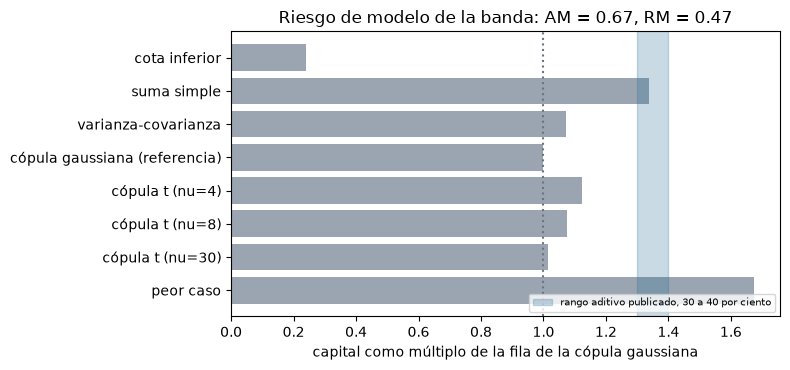

In [6]:
# La banda como múltiplo de la referencia gaussiana, con el rango aditivo publicado sombreado
multiple = [c / measures.rho_x0 for c in capitals]
names = [NAMES[m] + (f" (nu={nu:g})" if nu else "") for m, nu in labels]
published = "rango aditivo publicado, 30 a 40 por ciento"
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label=published)
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital como múltiplo de la fila de la cópula gaussiana")
ax.set_title(f"Riesgo de modelo de la banda: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

El conjunto de modelos es amplio. La referencia gaussiana es 491.974 millones de pesos y las ocho filas van desde 118.518
millones, la cota inferior, hasta 823.332 millones, el peor caso, una razón de 6,95. El multiplicador de recargo es 0,6735, de
modo que multiplicar la referencia por 1,67 alcanza el peor caso, y la medida relativa es 0,4701: la referencia queda a 47 por
ciento del camino desde el peor caso hacia el mejor. La franja sombreada es lo que Rosenberg y Schuermann esperarían para la
suma simple sobre una cifra diversificada, y la barra de la suma simple cae en ella, pero la dispersión del conjunto es mucho
más ancha que el rango del artículo.

### Medida 2: el peor caso dentro de un presupuesto de entropía

El conjunto de Barrieu y Scandolo es el conjunto de modelos que el analista escribió. Glasserman y Xu (2014) hacen otra pregunta: **¿cuán equivocado puede estar el modelo de referencia, de una manera medible, antes de que una cantidad cambie cuánto?** Se toma la ley base de una pérdida $V$ (aquí el agregado de la cópula gaussiana) y se consideran todas las leyes alternativas con razón de verosimilitud $m \ge 0$, $E[m] = 1$, cuya **entropía relativa** respecto de la base es a lo más un presupuesto $\eta$. La peor pérdida esperada es

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

con $\theta > 0$ elegido de modo que la restricción de entropía se active: el peor caso **inclina** la muestra base hacia sus pérdidas grandes, de forma exponencial. Cuesta solo un reponderado de la simulación base. `glasserman_xu_worst_case(v, budget)` devuelve la inclinación $\theta$, la entropía alcanzada, la media base y la media del peor caso, y rechaza un presupuesto que la muestra no puede alcanzar (la entropía de una inclinación es a lo más $\log S$).

El caso usa el presupuesto $\eta = 0,05$ sobre el agregado gaussiano.

La celda siguiente ejecuta `glasserman_xu_worst_case` sobre el agregado simulado del paso 1 con presupuestos de 0,005 a 0,25,
imprime cuatro de ellos y el rechazo de uno inalcanzable.

In [7]:
# El peor caso de Glasserman-Xu dentro de un presupuesto de entropía: un barrido de presupuestos, cuatro
# impresos y un rechazo
budgets = np.linspace(0.005, 0.25, 25)
runs = [model_risk.glasserman_xu_worst_case(total, b) for b in budgets]
print("presupuesto, inclinación, entropía, base, peor caso, razón")
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    row = (budget, gx.theta, gx.relative_entropy, gx.baseline, gx.worst_case, gx.worst_case / gx.baseline)
    print("%5.2f %10.3e %7.4f %11.1f %11.1f %5.2f" % row)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("versionado, presupuesto 0,05")
print(round(committed_gx["baseline_clp_m"], 1), round(committed_gx["worst_case_clp_m"], 1))
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError:
    print("un presupuesto que la muestra no alcanza es rechazado")

presupuesto, inclinación, entropía, base, peor caso, razón
 0.01  6.367e-07  0.0100     66898.7     88454.2  1.32
 0.05  7.878e-07  0.0500     66898.7    143206.7  2.14
 0.10  8.497e-07  0.1000     66898.7    204035.3  3.05
 0.20  9.114e-07  0.2000     66898.7    317194.7  4.74
versionado, presupuesto 0,05
66898.5 143201.8
un presupuesto que la muestra no alcanza es rechazado


La celda siguiente dibuja la peor pérdida esperada del barrido como múltiplo de la base, con el presupuesto del caso marcado.

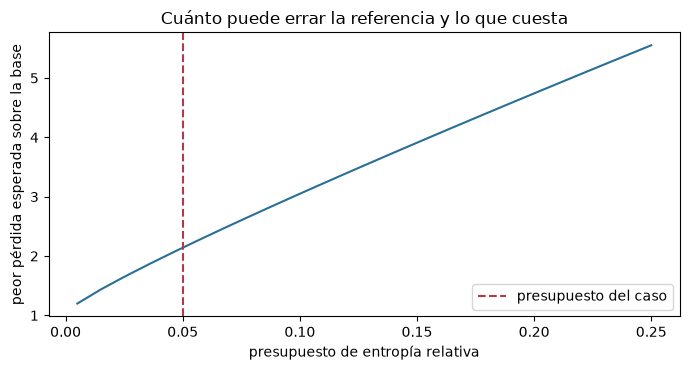

In [8]:
# La peor pérdida esperada sobre la base cuando crece el presupuesto de entropía
ratio = [r.worst_case / r.baseline for r in runs]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(budgets, ratio, color="#2a6f97")
ax.axvline(0.05, color="#b23a48", linestyle="--", label="presupuesto del caso")
ax.set_xlabel("presupuesto de entropía relativa")
ax.set_ylabel("peor pérdida esperada sobre la base")
ax.set_title("Cuánto puede errar la referencia y lo que cuesta")
ax.legend()
fig.tight_layout()
plt.show()

El presupuesto de entropía convierte una duda de modelado en un número. Sobre el agregado simulado, cuya media base es 66.899
millones de pesos, la peor pérdida esperada con un presupuesto de 0,01; 0,05; 0,10 y 0,20 es 88.454; 143.207; 204.035 y
317.195, que son 1,32; 2,14; 3,05 y 4,74 veces la base. Con el presupuesto del caso, 0,05, coincide con el bloque versionado,
143.202. La curva es convexa: el peor caso crece más rápido que el presupuesto porque el agregado tiene cola pesada, y cuanta
más cola tiene la base, más puede mover su media un presupuesto dado. Un presupuesto que la muestra no alcanza, sobre log S de
3,91, se rechaza.

### Medir el resto de la tabla

La celda siguiente lee de los documentos versionados aquello en que se puede medir cada fila restante de la tabla: el exceso
aditivo frente al rango publicado de Rosenberg y Schuermann, la dispersión de las filas de cópula sobre la gaussiana, la mezcla
de negocios del capital, y las razones de picos de la retroproyección de los satélites que representan la fila de modelos
supervisores.

In [9]:
# Medir en los documentos versionados aquello en que se puede medir cada fila restante de la tabla
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference_doc = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
overestimate = agg_tests.rosenberg_schuermann_reference(simple_sum, gaussian)
print("exceso aditivo (motor)", round(overestimate.statistic, 4))
print("rango publicado", reference_doc["published_additive_overestimate"])
copula_rows = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("dispersión de las filas de cópula sobre la gaussiana", round(max(copula_rows) / gaussian - 1, 4))
mix = {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in marginals}
print("mezcla de negocios, parte de la suma simple", mix)
capitals_all = [r["capital_clp_m"] for r in band]
print("peor caso sobre cota inferior", round(max(capitals_all) / min(capitals_all), 2))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
peaks = [round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast]
print("razones de picos de la retroproyección", peaks)

exceso aditivo (motor) 0.3376
rango publicado {'low': 0.3, 'high': 0.4}
dispersión de las filas de cópula sobre la gaussiana 0.1228
mezcla de negocios, parte de la suma simple {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
peor caso sobre cota inferior 6.95
razones de picos de la retroproyección [4.55, 13.14, 252.13, 4.3, 2.09]


### Un pronóstico condicional VAR y el crecimiento en riesgo junto a los satélites

Los satélites de estrés de este caso son regresiones MCO de la tasa de castigos de cada tipo de préstamo, a través de su enlace,
sobre la trayectoria macroeconómica del escenario. La investigación (dossier 05) nombra dos métodos actuales que la práctica de la
propia Junta y la literatura usan junto a ellos. Un vector autorregresivo trata la tasa, el desempleo y el crecimiento del PIB como
un solo sistema, de modo que un escenario dado solo para el PIB mueve el desempleo y la tasa a través de la dinámica estimada: el
pronóstico condicional de Waggoner y Zha (1999), que `stress.scenario_models` del motor implementa período a período. El crecimiento
en riesgo (Adrian, Boyarchenko y Giannone 2019) regresiona el crecimiento del año siguiente sobre las condiciones actuales en varios
cuantiles, de modo que la cola izquierda puede responder a las condiciones financieras más que la mediana. El producto corre ambos
sobre la historia de la Junta (`pipeline.cases.c18.stress_rungs`); esa historia se lee de la raíz de datos, así que este notebook
corre primero los dos métodos sobre un sistema cuya respuesta se conoce.

In [10]:
# Un VAR(1) conocido del crecimiento trimestral del PIB (%), el desempleo (%) y el probit de una tasa de castigos
from riskvalidation.stress import scenario_models as sm
from scipy.stats import norm

A = np.array([[0.45, -0.10, 0.00], [-0.12, 0.92, 0.00], [-0.035, 0.030, 0.88]])
c = np.array([1.6, 0.55, -0.38])
cov = np.array([[2.2, -0.25, -0.02], [-0.25, 0.09, 0.004], [-0.02, 0.004, 0.0025]])
mean = np.linalg.solve(np.eye(3) - A, c)
rng = np.random.default_rng(20261030)
y = np.empty((140, 3))
y[0] = mean
shocks = rng.multivariate_normal(np.zeros(3), cov, size=140)
for t in range(1, 140):
    y[t] = c + A @ y[t - 1] + shocks[t]
train = y[:132]
fit = sm.fit_var(train, 1)
error = np.array(fit.coefficients[0]) - A
rate_label = "tasa de castigos en la media del sistema"
print(f"{rate_label}: {100 * norm.cdf(mean[2]):.3f} %")
for name, row in zip(("ecuación del PIB", "ecuación del desempleo", "ecuación de la tasa"), error):
    print(f"{name:22s}", " ".join(f"{v:+.3f}" for v in row))


tasa de castigos en la media del sistema: 0.150 %
ecuación del PIB       +0.018 +0.392 +0.801
ecuación del desempleo -0.015 -0.127 -0.051
ecuación de la tasa    -0.002 +0.001 -0.004


La media del sistema pone la tasa de castigos en 0,149 %, una cartera tranquila. La ecuación de la tasa ajustada queda a
unas milésimas de sus coeficientes verdaderos, mientras los coeficientes de la ecuación del PIB sobre el desempleo y sobre la tasa
se desvían en 0,392 y 0,801: esas dos series casi no se mueven de un trimestre a otro, así que 132 trimestres dicen poco sobre su
efecto en el crecimiento. Un pronóstico condicional lee la ecuación de la tasa, que es la que el ajuste acierta. La celda siguiente
impone una recesión solo al PIB y deja que el sistema la lleve a la tasa.

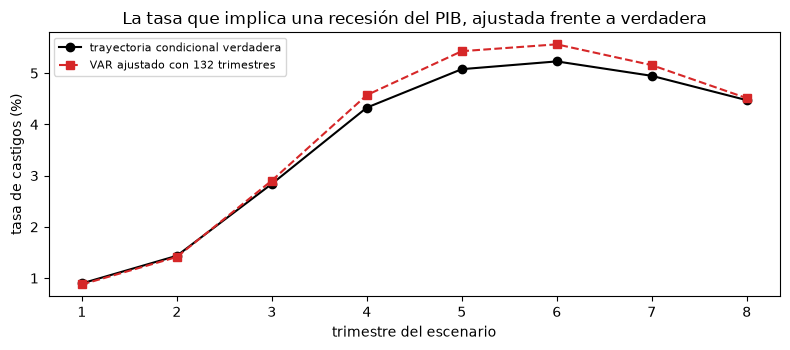

fitted 0.88 1.41 2.90 4.57 5.43 5.56 5.16 4.51
true   0.90 1.44 2.84 4.33 5.08 5.23 4.95 4.47


In [11]:
# Una recesión dada solo para el PIB durante ocho trimestres: las trayectorias condicionales ajustada y verdadera
path = np.array([[-2.5], [-6.0], [-4.0], [-1.0], [0.5], [1.5], [2.0], [2.2]])
fitted = sm.var_conditional_forecast(fit, train[-1:], path, [0])
true = np.empty((8, 3))
prev = train[-1]
for h in range(8):
    free = c + A @ prev
    shock_gdp = path[h, 0] - free[0]
    true[h] = np.r_[path[h, 0], free[1:] + cov[1:, 0] / cov[0, 0] * shock_gdp]
    prev = true[h]
quarters = np.arange(1, 9)
fig, ax = plt.subplots(figsize=(8, 3.6))
true_label = "trayectoria condicional verdadera"
fitted_label = "VAR ajustado con 132 trimestres"
ax.plot(quarters, 100 * norm.cdf(true[:, 2]), color="black", marker="o", label=true_label)
ax.plot(quarters, 100 * norm.cdf(fitted[:, 2]), "--", color="tab:red", marker="s", label=fitted_label)
ax.set_xlabel("trimestre del escenario")
ax.set_ylabel("tasa de castigos (%)")
ax.set_title("La tasa que implica una recesión del PIB, ajustada frente a verdadera")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("fitted", " ".join(f"{v:.2f}" for v in 100 * norm.cdf(fitted[:, 2])))
print("true  ", " ".join(f"{v:.2f}" for v in 100 * norm.cdf(true[:, 2])))


La trayectoria condicional ajustada sigue a la verdadera: ambas suben desde cerca de 0,9 % a un máximo en el sexto
trimestre, 5,56 % ajustada contra 5,23 % verdadera, y bajan cuando el PIB se recupera. La brecha, un tercio de punto en el máximo,
viene de la persistencia estimada de la tasa (el coeficiente de su propio rezago), que un VAR necesita para llevar un shock hacia
adelante. El satélite MCO necesitaría la trayectoria del desempleo como entrada; aquí la entrega el sistema, que es la
razón para usar un VAR, y también su riesgo: un error en la dinámica entra en cada trimestre del escenario.

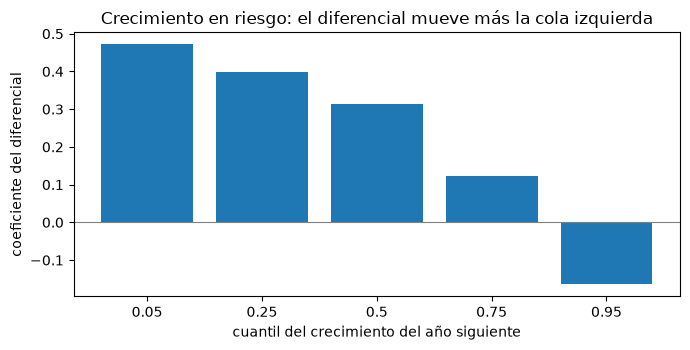

slope on the spread +0.472 +0.398 +0.314 +0.124 -0.165
held-out coverage   0.080 0.267 0.533 0.753 0.953
skewed t of the first origin: mu 2.159, sigma 0.996, alpha 0.864, nu 4.55


In [12]:
# Crecimiento en riesgo: regresiones cuantílicas del crecimiento del año siguiente sobre el actual y un diferencial
n = 600
g_now = rng.normal(2.0, 1.5, n)
spread = rng.normal(1.0, 1.0, n)
width = 0.8 + 0.6 * np.exp(-spread)
g_next = 0.6 + 0.6 * g_now + 0.3 * spread + width * rng.standard_t(6, n) * 0.8
X = np.column_stack([np.ones(n), g_now, spread])
taus = (0.05, 0.25, 0.5, 0.75, 0.95)
coef = sm.gar_quantile_regressions(g_next[:450], X[:450], taus)
q = X[450:] @ coef.T
cover = [(g_next[450:] < q[:, k]).mean() for k in range(len(taus))]
first = sm.fit_skewed_t_to_quantiles(q[0], taus)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([str(t) for t in taus], coef[:, 2], color="tab:blue")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("cuantil del crecimiento del año siguiente")
ax.set_ylabel("coeficiente del diferencial")
ax.set_title("Crecimiento en riesgo: el diferencial mueve más la cola izquierda")
fig.tight_layout()
plt.show()
print("slope on the spread", " ".join(f"{v:+.3f}" for v in coef[:, 2]))
print("held-out coverage  ", " ".join(f"{v:.3f}" for v in cover))
shape = f"mu {first.mu:.3f}, sigma {first.sigma:.3f}, alpha {first.alpha:.3f}, nu {first.nu:.2f}"
print("skewed t of the first origin:", shape)


El coeficiente del diferencial cae de +0,472 en el cuantil 5 % a -0,165 en el 95 %: un diferencial estrecho (valores bajos)
baja la cola izquierda del crecimiento del año siguiente mucho más que la mediana, que es la vulnerabilidad que el crecimiento en
riesgo está hecho para encontrar. Los cuantiles ajustados sobre 450 orígenes cubren 0,080, 0,267, 0,533, 0,753 y 0,953 de los 150
reservados, cerca de sus niveles nominales, y la t de Student asimétrica ajustada a los cuantiles del primer origen tiene un sesgo
negativo (alfa 0,864) y 4,55 grados de libertad. El retro-pronóstico del producto sobre la historia de la Junta es la prueba que
cuenta.

In [13]:
# El retro-pronóstico del producto de ambos peldaños sobre la historia de la Junta (C18): ventanas, signos, veredictos
stress = next(m for m in read_json("C18/models-banco-andino.json")["model"] if "var" in m.get("details", {}))
details = stress["details"]
closer_label = "más cerca que MCO"
red_label = "chequeos de signo en rojo"
wrong_label = "coeficientes de signo equivocado"
for w in details["var"]["summary"]:
    closer = f"{w['var_closer']} / {w['loan_types']}"
    print(f"{w['window_id']:14s} VAR {closer_label} {closer} | {red_label} {w['sign_checks_red']}")
acceptance = details["acceptance"]
print(f"VAR {wrong_label}: {acceptance['var_wrong_signs']} / {acceptance['var_sign_checks']}")
print(f"GaR {wrong_label}: {acceptance['gar_wrong_signs']} / {acceptance['gar_sign_checks']}")
print(details["statement"]["es"])


gfc-2008-09    VAR más cerca que MCO 1 / 5 | chequeos de signo en rojo 4
pandemic-2020  VAR más cerca que MCO 5 / 5 | chequeos de signo en rojo 5
VAR coeficientes de signo equivocado: 9 / 10
GaR coeficientes de signo equivocado: 2 / 10
Crisis financiera global, 2008 T1 a 2009 T4, ajustada hasta 2007 T4: el VAR queda más cerca de las tasas realizadas que el satélite MCO en 1 de 5 tipos de préstamo; Ventana de la pandemia, 2020 T1 a 2025 T4, ajustada hasta 2019 T4: el VAR queda más cerca de las tasas realizadas que el satélite MCO en 5 de 5 tipos de préstamo; Crisis financiera global, 2008 T1 a 2009 T4, ajustada hasta 2007 T4: los cuantiles de crecimiento en riesgo puntúan 0,99 de la pérdida pinball de los cuantiles incondicionales en 5 orígenes (bajo 1); Ventana de la pandemia, 2020 T1 a 2025 T4, ajustada hasta 2019 T4: los cuantiles de crecimiento en riesgo puntúan 1,27 de la pérdida pinball de los cuantiles incondicionales en 21 orígenes (no bajo 1).


Sobre la historia real el cuadro se divide. En la ventana 2008-09 el VAR queda más cerca de los castigos realizados que el
satélite MCO en un tipo de préstamo de cinco; en la ventana de la pandemia en los cinco, porque los satélites sobrepasaron una
recesión que la respuesta fiscal impidió que llegara a las carteras. Nueve de los diez signos esperados de las ecuaciones de la tasa
del VAR son equivocados, contra dos de diez del crecimiento en riesgo, y el crecimiento en riesgo gana al cuantil incondicional en
2008-09 (0,99 de su pérdida pinball en cinco orígenes) pero no en la ventana de la pandemia (1,27 en 21). El nivel está replicado y
corre, y su veredicto es mixto: el sistema pronostica mejor la pandemia y peor la crisis, con coeficientes que un validador no
aprobaría.

### Sensibilidad: dónde el método cambia o se quiebra

Las dos medidas de este notebook responden una pregunta que depende de lo que el analista escribió. El multiplicador de recargo y la medida relativa se definen sobre un conjunto de modelos y un modelo de referencia dentro de él, de modo que los mismos capitales dan números distintos con otra referencia o con otro conjunto. El peor caso de Glasserman y Xu se calcula inclinando una muestra simulada, y una inclinación demasiado fuerte deja a un puñado de simulaciones con todo el peso. El barrido pregunta dónde deja de ser informativa cada medida. Para la muestra inclinada el peso de la simulación $s$ es $w_s \propto e^{\theta V_s}$, con $V_s$ la pérdida simulada y $\theta$ la inclinación del presupuesto, y el número efectivo de simulaciones es

$$n_{\mathrm{eff}} = \frac{\left(\sum_{s=1}^{S} w_s\right)^{2}}{\sum_{s=1}^{S} w_s^{2}},$$

que es igual al tamaño de muestra $S$ cuando los pesos son iguales y baja a 1 cuando una sola simulación los lleva todos. La celda siguiente calcula el multiplicador de recargo AM y la medida relativa RM con cada una de las ocho filas de la banda como referencia, luego con la fila gaussiana como referencia sobre tres conjuntos, la banda completa, la banda sin el peor caso y la banda sin las dos cotas, y el número efectivo de simulaciones de las veinticinco muestras inclinadas del barrido de presupuestos.

In [14]:
# Tomar cada fila de la banda como referencia, sacar las cotas y medir la muestra tras la inclinación
by_reference = [model_risk.barrieu_scandolo(capitals, k) for k in range(len(capitals))]
kinds = [row["method"] for row in band]
gauss_index = labels.index(("gaussian-copula", None))
sets = {"las ocho filas": list(range(8)),
        "sin el peor caso": [k for k in range(8) if kinds[k] != "worst-case"],
        "sin las dos cotas": [k for k in range(8) if kinds[k] not in ("lower-bound", "worst-case")]}
by_set = {}
for name, keep in sets.items():
    by_set[name] = model_risk.barrieu_scandolo([capitals[k] for k in keep], keep.index(gauss_index))
weights = [np.exp(r.theta * (total - total.max())) for r in runs]
ess = [float(w.sum() ** 2 / (w ** 2).sum()) / total.size for w in weights]
print("por modelo de referencia:")
for label, r in zip(labels, by_reference):
    print(f"{label[0]:22s} {str(label[1]):5s} AM {r.am:7.4f} RM {r.rm:6.4f}")
print("por conjunto de modelos, referencia gaussiana:")
for name, r in by_set.items():
    print(f"{name:34s} AM {r.am:7.4f} RM {r.rm:6.4f}")
print("presupuestos", [round(float(b), 3) for b in budgets[[0, 4, 9, 14, 19, 24]]])
print("parte efectiva de la muestra", [round(ess[k], 4) for k in (0, 4, 9, 14, 19, 24)])


por modelo de referencia:
lower-bound            None  AM  5.9469 RM 1.0000
simple-sum             None  AM  0.2512 RM 0.2345
variance-covariance    None  AM  0.5590 RM 0.4189
gaussian-copula        None  AM  0.6735 RM 0.4701
t-copula               4.0   AM  0.4905 RM 0.3844
t-copula               8.0   AM  0.5584 RM 0.4186
t-copula               30.0  AM  0.6495 RM 0.4600
worst-case             None  AM  0.0000 RM 0.0000
por conjunto de modelos, referencia gaussiana:
las ocho filas                     AM  0.6735 RM 0.4701
sin el peor caso                   AM  0.3376 RM 0.3078
sin las dos cotas                  AM  0.3376 RM 1.0000
presupuestos [0.005, 0.046, 0.097, 0.148, 0.199, 0.25]
parte efectiva de la muestra [0.8121, 0.0436, 0.0109, 0.005, 0.0029, 0.0019]


Las medidas ya se calcularon; la celda siguiente dibuja AM y RM para cada elección de referencia en el panel izquierdo y, en el panel derecho, la parte de los un millón de simulaciones que usa efectivamente la inclinación con cada presupuesto, en un eje logarítmico, con el presupuesto del caso marcado.

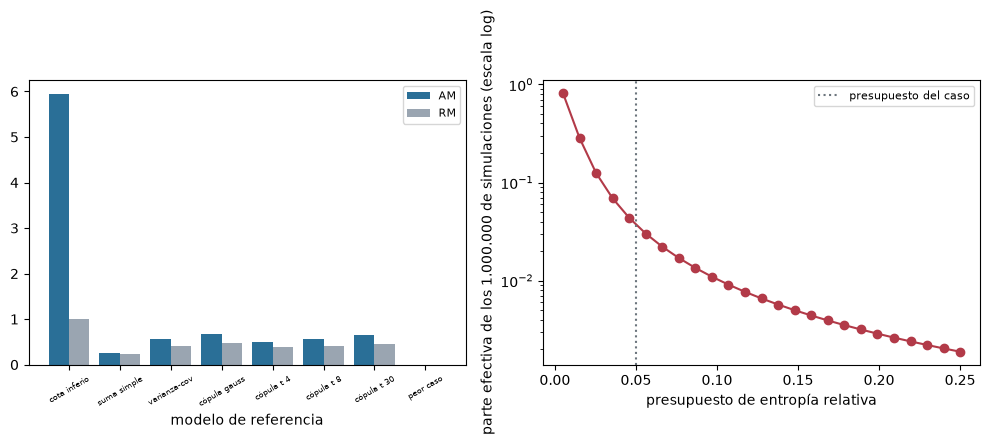

simulaciones efectivas, presupuestos 0,005, 0,10, 0,25 [812078, 10948, 1883]


In [15]:
# Dibujar AM y RM por modelo de referencia, y el tamaño efectivo de muestra frente al presupuesto
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
tags = [NAMES[m][:12] + (f" {nu:g}" if nu else "") for m, nu in labels]
axes[0].bar(np.arange(8) - 0.2, [r.am for r in by_reference], width=0.4, color="#2a6f97", label="AM")
axes[0].bar(np.arange(8) + 0.2, [r.rm for r in by_reference], width=0.4, color="#9aa5b1", label="RM")
axes[0].set_xticks(range(8))
axes[0].set_xticklabels(tags, fontsize=6, rotation=30)
axes[0].set_xlabel("modelo de referencia")
axes[0].legend(fontsize=8)
axes[1].semilogy(budgets, ess, marker="o", color="#b23a48")
axes[1].axvline(0.05, color="#6c757d", linestyle=":", label="presupuesto del caso")
axes[1].set_xlabel("presupuesto de entropía relativa")
axes[1].set_ylabel("parte efectiva de los 1.000.000 de simulaciones (escala log)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
counts = [round(float(ess[k] * total.size)) for k in (0, 9, 24)]
print("simulaciones efectivas, presupuestos 0,005, 0,10, 0,25", counts)


El panel izquierdo muestra que el riesgo de modelo es una propiedad de la referencia tanto como del conjunto. Con la cota inferior como referencia el multiplicador de recargo es 5,9469 y la medida relativa 1,0000, con el peor caso como referencia ambos son 0, y la fila gaussiana, la elección del caso, da 0,6735 y 0,4701; las otras filas dan una medida relativa de 0,2345 (la suma simple) a 0,4600 (la cópula t con 30 grados de libertad). Elegir otra referencia mueve AM de 0 a 5,95 y RM de 0 a 1, de modo que una cifra de riesgo de modelo sin su referencia no es un número. El conjunto importa igual. Sacar el peor caso reduce a la mitad el multiplicador, de 0,6735 a 0,3376, y sacar las dos cotas deja el mismo 0,3376 pero hace de la fila gaussiana la mejor del conjunto, RM 1,0000, en vez de estar a 47 por ciento del camino. Ese 0,3376 es el sobrestimado aditivo del notebook 01, porque sin las cotas la suma simple es la peor fila, y queda dentro del 30 a 40 por ciento de Rosenberg y Schuermann: la misma banda, leída con y sin sus cotas, da un multiplicador de riesgo de modelo de 0,34 o de 0,67.

El panel derecho es el límite de la inclinación de entropía. Con un presupuesto de 0,005 la inclinación mantiene efectivamente en uso 81 por ciento del millón de simulaciones (812.078); con un presupuesto de 0,046 mantiene 4,4 por ciento, con 0,097 cerca de 1,1 por ciento (10.948) y con 0,25 cerca de 0,19 por ciento (1.883). El presupuesto del caso, 0,05, queda donde la muestra ya perdió más de diecinueve de cada veinte simulaciones, de modo que su peor pérdida esperada descansa en unas pocas decenas de miles de simulaciones, aún suficientes para leerla, mientras que con 0,25 descansa en menos de dos mil y su cola es la de la muestra y no la de la pérdida. Donde el método se quiebra: un presupuesto mayor que el que la muestra puede cargar repondera el ruido de la cola, y el motor rechaza solo los presupuestos sobre el logaritmo del tamaño de muestra, no los que apenas dejan muestra. El barrido varía el presupuesto sobre una simulación con la semilla del caso.

### Úsalo con tus propios datos

Las dos medidas reciben números simples. `barrieu_scandolo` necesita el capital de cada modelo de tu conjunto, en una unidad de dinero y sobre una base, y el índice del modelo de referencia; `glasserman_xu_worst_case` necesita una muestra de la pérdida cuya esperanza cuestionas y un presupuesto. Ambas devuelven un resultado cuyos números el producto escribe en el bloque `model_risk` de un documento de agregación, con la etiqueta `information-not-capital`. El contrato es `engine-aggregation-api` (`docs/contracts/engine/aggregation-api.md`), que fija las dos firmas, sus rechazos (una referencia fuera del conjunto, un presupuesto que la muestra no puede alcanzar) y los campos del bloque.

La celda siguiente lee el bloque que el documento base versiona y lista los campos del bloque, del resultado de Barrieu y Scandolo y del resultado de Glasserman y Xu, y comprueba la identidad que los une: el capital de referencia por $1 + \mathrm{AM}$ es el peor capital del conjunto.

In [16]:
# Leer el bloque de riesgo de modelo versionado y listar sus campos
block = agg["model_risk"]
print("campos de primer nivel de model_risk", sorted(block))
print("campos de barrieu_scandolo", sorted(block["barrieu_scandolo"]))
print("campos de glasserman_xu", sorted(block["glasserman_xu"]))
print("estado, conjunto y referencia", block["status"], block["set_of_models"], block["reference_model"])
bs = block["barrieu_scandolo"]
worst_row = bs["rho_x0_clp_m"] * (1 + bs["am"])
print("la referencia por (1 + AM) es la peor fila", np.isclose(worst_row, bs["rho_max_clp_m"]))


campos de primer nivel de model_risk ['barrieu_scandolo', 'glasserman_xu', 'label', 'reference_model', 'set_of_models', 'status']
campos de barrieu_scandolo ['am', 'rho_max_clp_m', 'rho_min_clp_m', 'rho_x0_clp_m', 'rm']
campos de glasserman_xu ['baseline_clp_m', 'quantity', 'relative_entropy_budget', 'theta', 'worst_case_clp_m']
estado, conjunto y referencia information-not-capital band-rows {'method': 'gaussian-copula', 'nu': None}
la referencia por (1 + AM) es la peor fila True


El bloque `model_risk` tiene seis campos: `status` y `label`, que dicen que es información y no capital, `set_of_models`, aquí las filas de la banda, el `reference_model` y los dos resultados. `barrieu_scandolo` contiene el capital de referencia (`rho_x0_clp_m`), el peor y el mejor del conjunto (`rho_max_clp_m`, `rho_min_clp_m`) y las dos medidas `am` y `rm`; `glasserman_xu` contiene la pérdida esperada base y la del peor caso, el presupuesto, la inclinación `theta` y la `quantity` que cuestiona. La identidad se cumple: el capital de referencia por $1 + \mathrm{AM}$ es la peor fila.

Para usar las medidas con números propios, la celda siguiente hace dos cosas. Lee la banda con estrés de mercado y crédito del segundo documento versionado, las mismas ocho filas calculadas con la correlación subida a 0,8, y mide su riesgo de modelo con la fila gaussiana como referencia; y sortea 200.000 pérdidas de una ley lognormal con semilla fija, que ocupa el lugar de tus propias pérdidas simuladas, y llama a `glasserman_xu_worst_case` sobre ellas con el presupuesto del caso de 0,05.

In [17]:
# Tus propios números: la banda estresada como conjunto de modelos, y un peor caso sobre una muestra tuya
stressed = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]["aggregation"]["band"]
stress_caps = [row["capital_clp_m"] for row in stressed]
stress_labels = [(row["method"], row["nu"]) for row in stressed]
mine_bs = model_risk.barrieu_scandolo(stress_caps, stress_labels.index(("gaussian-copula", None)))
base_bs = model_risk.barrieu_scandolo(capitals, reference)
rng = np.random.default_rng(11)
my_losses = rng.lognormal(10.0, 1.1, 200_000)
my_gx = model_risk.glasserman_xu_worst_case(my_losses, 0.05)
print("banda base, AM y RM", round(base_bs.am, 4), round(base_bs.rm, 4))
print("banda estresada, AM y RM", round(mine_bs.am, 4), round(mine_bs.rm, 4))
print("referencia estresada, millones de CLP", round(mine_bs.rho_x0))
print("peor y mejor del conjunto estresado", round(mine_bs.rho_max), round(mine_bs.rho_min))
print("tu muestra: base y peor caso", round(my_gx.baseline), round(my_gx.worst_case))
print("peor caso sobre base", round(my_gx.worst_case / my_gx.baseline, 3))
print("entropía alcanzada e inclinación", round(my_gx.relative_entropy, 4), f"{my_gx.theta:.3e}")


banda base, AM y RM 0.6735 0.4701
banda estresada, AM y RM 0.4927 0.3856
referencia estresada, millones de CLP 551569
peor y mejor del conjunto estresado 823332 118517
tu muestra: base y peor caso 40174 81801
peor caso sobre base 2.036
entropía alcanzada e inclinación 0.05 1.516e-06


En la banda estresada el multiplicador de recargo es 0,4927 y la medida relativa 0,3856, frente a 0,6735 y 0,4701 en la banda base. Las dos cotas, 118.517 y 823.332 millones, no se movieron, pero la referencia gaussiana sí, de 491.974 a 551.569, más cerca del peor caso, de modo que el multiplicador baja: una cifra de riesgo de modelo leída sola llamaría a la cartera más correlacionada menos expuesta a su modelo, cuando su capital subió 12 por ciento. Las dos medidas deben leerse con el capital al que se refieren. En tu muestra la peor pérdida esperada dentro del presupuesto de 0,05 es 81.801 frente a una base de 40.174, 2,036 veces, cercana a las 2,14 del caso sobre su agregado de cola pesada, con la entropía alcanzada en 0,05 y una inclinación de 1,516e-06.

Qué revisar en tu propia salida: que el conjunto y la referencia estén escritos junto al resultado; que cada capital del conjunto esté en la misma unidad de dinero y sobre la misma base; que `glasserman_xu_worst_case` alcance el presupuesto, lo que muestra la entropía impresa de 0,05; y el tamaño efectivo de muestra, que el barrido mostró que cae rápido cuando crece el presupuesto. Lo que esto no muestra: la muestra lognormal ocupa el lugar de tu propia simulación.

La tabla de este notebook empieza con un método que no se puede correr aquí, los modelos supervisores de la Reserva Federal, que es también el método que el producto planifica como su réplica supervisora. Su estructura publicada es una pérdida por facilidad,

$$\mathrm{EL} = \sum_{i} \mathrm{PD}_i \times \mathrm{LGD}_i \times \mathrm{EAD}_i,$$

donde $\mathrm{PD}_i$, $\mathrm{LGD}_i$ y $\mathrm{EAD}_i$ son la probabilidad de incumplimiento, la pérdida dado el incumplimiento y la exposición al incumplimiento de la facilidad $i$, con la PD proveniente de regresiones sobre el diferencial BBB (Reserva Federal, documentación de modelos de riesgo de crédito, otoño de 2026, en las referencias). Reproducir con ella las tasas de pérdida publicadas de las carteras hipotéticas es el criterio de aceptación de esa réplica, y los registros versionados dicen que aquí no se cumple: el notebook 09 lee los tres registros que mantienen planificada la réplica, el contrato del motor no tiene función ni prueba supervisora, y ningún documento versionado contiene una tasa de pérdida publicada. Este notebook enseña la estructura y la comparación y no informa ninguna réplica.

## Resultados

El caso queda dentro de la práctica publicada en los puntos donde se puede medir, y su distancia a ella se declara. El exceso
aditivo de 0,3376 está dentro del rango publicado de 30 a 40 por ciento, la cópula t con cuatro grados de libertad queda 12,3
por ciento sobre la gaussiana, un efecto de cópula mayor que el modesto del artículo, y las razones de picos de la
retroproyección, 2,09 a 252,13, dicen que la pérdida de crédito estresada se apoya en satélites que fallan su propia validación
(notebook 07).

**Respuesta:** una sola cifra de capital esconde mucho. La referencia gaussiana de 491.974 millones de pesos está a 47 por
ciento del camino desde el peor caso de 823.332 millones hasta el mejor de 118.518, el multiplicador de recargo es 0,6735 (el
peor caso es 1,67 veces la referencia), y un presupuesto de entropía de 0,05 sobre el agregado simulado levanta su pérdida
esperada de 66.899 a 143.207 millones, 2,14 veces, con 4,74 veces con un presupuesto de 0,20. Lo que le falta al caso se
declara: los modelos de la Reserva Federal no pueden replicarse hasta una tasa de pérdida publicada desde el registro público,
las cópulas vine y el BVAR de Minnesota no están en el motor, y el primer paso del crecimiento en riesgo necesita un paquete
que este entorno no tiene.

Lo que este notebook no muestra: las cifras de Glasserman y Xu son sobre un agregado simulado desde una grilla de 1.961 puntos
por marginal, que coincide con el bloque versionado hasta 0,01 por ciento y no hasta el dígito; la tabla de la literatura publicada es
la de la investigación, con sus puntos NO VERIFICADOS marcados, no una revisión de literatura nueva; y ningún número de él es
un resultado regulatorio.

El pronóstico condicional VAR y el crecimiento en riesgo junto a los satélites corren y recuperan un sistema conocido (la trayectoria
condicional de la tasa llega a 5,56 % contra 5,23 % verdadera), pero sobre la historia de la Junta el VAR queda más cerca que MCO en
1 de 5 tipos de préstamo en 2008-09 y en 5 de 5 en la pandemia, con 9 de 10 signos esperados equivocados, y el crecimiento en riesgo
gana al cuantil incondicional solo en 2008-09.

## Resumen

- La práctica publicada tiene tres capas: modelos supervisores (Reserva Federal, EBA), generadores de escenarios (BVAR, GVAR, crecimiento en riesgo, cuantiles en panel) y agregación (cópulas, vines, la cautela del Joint Forum); el caso implementa una familia de satélites más simple, las reglas estáticas de la EBA, un VAR y la mecánica t asimétrica, y la escalera gaussiana, t y de peor caso.
- El riesgo de modelo sobre la banda se mide con el multiplicador de recargo y la medida relativa de Barrieu y Scandolo, que el motor recalcula exactamente desde los capitales versionados, y con el peor caso de Glasserman-Xu dentro de un presupuesto de entropía, que necesita el agregado simulado y lo inclina hacia sus pérdidas grandes.
- Ambas medidas son información de sensibilidad para el validador, rotuladas `information-not-capital`, y dicen lo que una sola cifra de capital oculta.
- Lo que el motor no tiene se declara, no se oculta: cópulas vine, el BVAR de Minnesota, el satélite de cuantiles en panel y el primer paso del crecimiento en riesgo (necesita `statsmodels`); los modelos de la Reserva Federal no pueden replicarse a una tasa de pérdida publicada desde el registro público.

**Qué probar a continuación.** Cambia el modelo de referencia del paso 1 a la cópula t con $\nu = 4$ y mira cómo se mueven el multiplicador de recargo y la medida relativa; luego sigue con el notebook 09, que convierte la banda en una afirmación y lee la preparación declarada del caso.

- El pronóstico condicional VAR y el crecimiento en riesgo recuperan un sistema conocido, pero sobre la historia de la Junta el VAR gana la pandemia y pierde la crisis con 9 de 10 signos equivocados.

## Referencias

- Glasserman, P. y Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. y Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation (avances en la modelación de la agregación de riesgos). https://www.bis.org/publ/joint25.pdf
- Banco de Pagos Internacionales (2010), comunicado de prensa del 21 de octubre de 2010 sobre el informe del Joint Forum Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026 (documentación de los modelos de crédito). https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. y Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. y Zakrajsek, E. (2014), el satélite de cuantiles en panel, y Pesaran, Schuermann y Weiner (2004), el VAR global, como los resume el dossier 05, H.2 (sin enlace: no se leyeron en la base de investigación de este repositorio).
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (las funciones de riesgo de modelo).

- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4), 1263-1289, https://doi.org/10.1257/aer.20161923
- Waggoner, D. F. y Zha, T. (1999), Conditional forecasts in dynamic multivariate models, Review of Economics and Statistics 81(4), 639-651, https://doi.org/10.1162/003465399558508